# How certain is the Chatbot Arena leaderboard? Results report, v1

STAT 236, Fall 2026: Harry Hu, Chloe Yu, Ender Yang, Chenxi Ge. Compiled on 2026-10-29.

This notebook collects the results of Step 0 and Q1–Q3 in one place. It reads only the committed outputs in `results/` and `docs/figures/` and runs no simulation; the README lists the scripts that produce them. The last section records the checks we ran on the code and results before writing it.

**Summary**

- **Step 0: is our "Arena method" really Arena's?** Yes. Refitting the public 2024 battles with Arena's own code reproduces the 2024 board, with a median rating difference of 0.06 points. Both the 2024 board and today's site build their rank spreads from uncorrected per-model 95% intervals.
- **Q1: how reliable is the rank spread?** In 1,000 simulated datasets, each model's rank spread contains its true rank 99.9% of the time. All 129 contain their true ranks at once only 90.9% of the time, short of the 95% one would want for a whole leaderboard.
- **Q2: can a multiplicity correction fix it?** Every correction we tried reaches 100% in the simulated 2024 world, at very different costs. Pairwise tests with Holm's step-down give the narrowest valid rank spreads: 11.3 ranks on average, against 8.0 for Arena and 13.6 for Bonferroni. The χ² set of Chiang et al. (2024) gives 33–43.
- **Q3: are category specialties real?** All four global tests reject "no specialties" at the smallest p-value the simulation can give, and Bonferroni flags 275 of 958 (model, category) pairs. Specialties certainly exist. How many there are depends on how well the null's noise level is calibrated (Section 6).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import Image, display
from scipy.stats import norm

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
read = lambda name, **kw: pd.read_csv(ROOT / "results" / name, **kw)
show = lambda name, width=760: display(Image(filename=str(ROOT / "docs/figures" / name), width=width))
pct = lambda x, d=1: f"{100 * x:.{d}f}%"

# Same surfaces, ink and rcParams as q1_figures.py
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]   # sequential blue, light -> dark
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

## 1. Step 0: is our "Arena method" Arena's method?

Everything later simulates Arena's method, so we first checked that our code reproduces what Arena publishes.

- **2024.** We refit the public battle dump (`clean_battle_20240814_public.json`, 1,657,517 battles after the official filter) with `arena-rank`, Arena's open-source ranking code. We compared the result with the official 2024-08-12 board (`elo_results_20240813.pkl`).
- **2026.** We checked the intervals of every 2026 Text board in `lmarena-ai/leaderboard-dataset`, and the rank spreads the site showed for the top 59 models of the 2026-10-08 Text board.

In [2]:
s0 = read("step0_comparison.csv", index_col=0)
d_battles, d_rating = s0.our_battles - s0.num_battles, s0.our_rating - s0.rating
matched = d_battles.abs() <= 10
gap = (s0.final_ranking - s0.R_recomputed).value_counts()
iv, rs26 = read("step0_2026_intervals.csv"), read("step0_2026_rank_spread.csv")
pd.DataFrame({"Result": {
    "2024: battle count within ±10 of the board": f"{matched.sum()} of {len(s0)} models (the rest are recent models the public dump only partly covers)",
    "2024: rating difference, median |diff|": f"{d_rating.abs().median():.2f} points ({d_rating[matched].abs().max():.2f} at most where counts match)",
    "2024: published interval half-width / bootstrap SD": "median 1.90; a marginal interval from 100 draws gives 1.88; Bonferroni would need 3.55",
    "2024: published rank vs 1 + #{L_j > U_m}": f"off by exactly 5 for {gap.get(5, 0)} models, 0–4 for the top {len(s0) - gap.get(5, 0)} (5 hidden models were ranked too)",
    "2026: half-width / SE on every Text board": f"{iv.ratio_min.min():.4f} to {iv.ratio_max.max():.4f} on {len(iv):,} boards, i.e. always 1.96",
    "2026: site's rank spreads reproduced by the blog formula": f"{int((rs26.best_equal & rs26.worst_equal).sum())} of {len(rs26)} models, both ends",
}})

,Result
2024: battle count within ±10 of the board,91 of 128 models (the rest are recent models t...
"2024: rating difference, median |diff|",0.06 points (0.30 at most where counts match)
2024: published interval half-width / bootstrap SD,median 1.90; a marginal interval from 100 draw...
2024: published rank vs 1 + #{L_j > U_m},"off by exactly 5 for 112 models, 0–4 for the t..."
2026: half-width / SE on every Text board,"1.9600 to 1.9600 on 4,773 boards, i.e. always ..."
2026: site's rank spreads reproduced by the blog formula,"59 of 59 models, both ends"


So our "Arena method" (arena-rank's Bradley–Terry fit, its per-model 95% sandwich intervals, and the blog's rank-spread formula) is the method behind the leaderboard, in 2024 and today. Neither version applies any multiplicity correction. Chiang et al. (2024) say the ranking needs one, and that is the gap the rest of the project studies.

## 2. Q1: how often does the rank spread contain the true rank?

**Design.** We treat the Bradley–Terry fit on the real 2024 battles as the truth. We keep the real matchups (3,457 model pairs, 1.66M battles), redraw every outcome from the true strengths, and rerun Arena's method. We repeated this 1,000 times. Each model's rank spread is [best, worst]: best = 1 + the number of models whose interval lies entirely above it, worst = 1 + the number of other models whose interval reaches above its lower end.

In [3]:
q1 = read("q1_summary.csv", index_col=0)
v, se = q1["value"], q1["mc_se"]
row = lambda k: f"{v[k]:.3f} ± {se[k]:.3f}"
pd.DataFrame({"Each model on its own": [row("score CI coverage, per model (nominal 0.95)"), row("rank spread coverage, per model")],
              "All 129 at once": [row("score CIs: all cover (simultaneous)"), row("rank spread coverage, simultaneous (all models)")]},
             index=["Score intervals contain the true score", "Rank spreads contain the true rank"])

,Each model on its own,All 129 at once
Score intervals contain the true score,0.948 ± 0.001,0.003 ± 0.002
Rank spreads contain the true rank,0.999 ± 0.000,0.909 ± 0.009


- **Each score interval is valid on its own (0.948), but they almost never all hold at once (0.003).** About 6.7 of the 129 miss in an average dataset.
- **The rank spread absorbs most of those misses.** A model is separated from another only when their intervals do not overlap at all, which is a stricter standard than testing their difference. So the rank spread is too conservative for a single model (99.9%) and slightly short of 95% for the whole table (90.9%, about 4.5 Monte Carlo SEs below).
- **Where ranks are unstable.** Rank spreads are widest where many models have nearly the same strength (ranks 61–100), not where models are weakest:

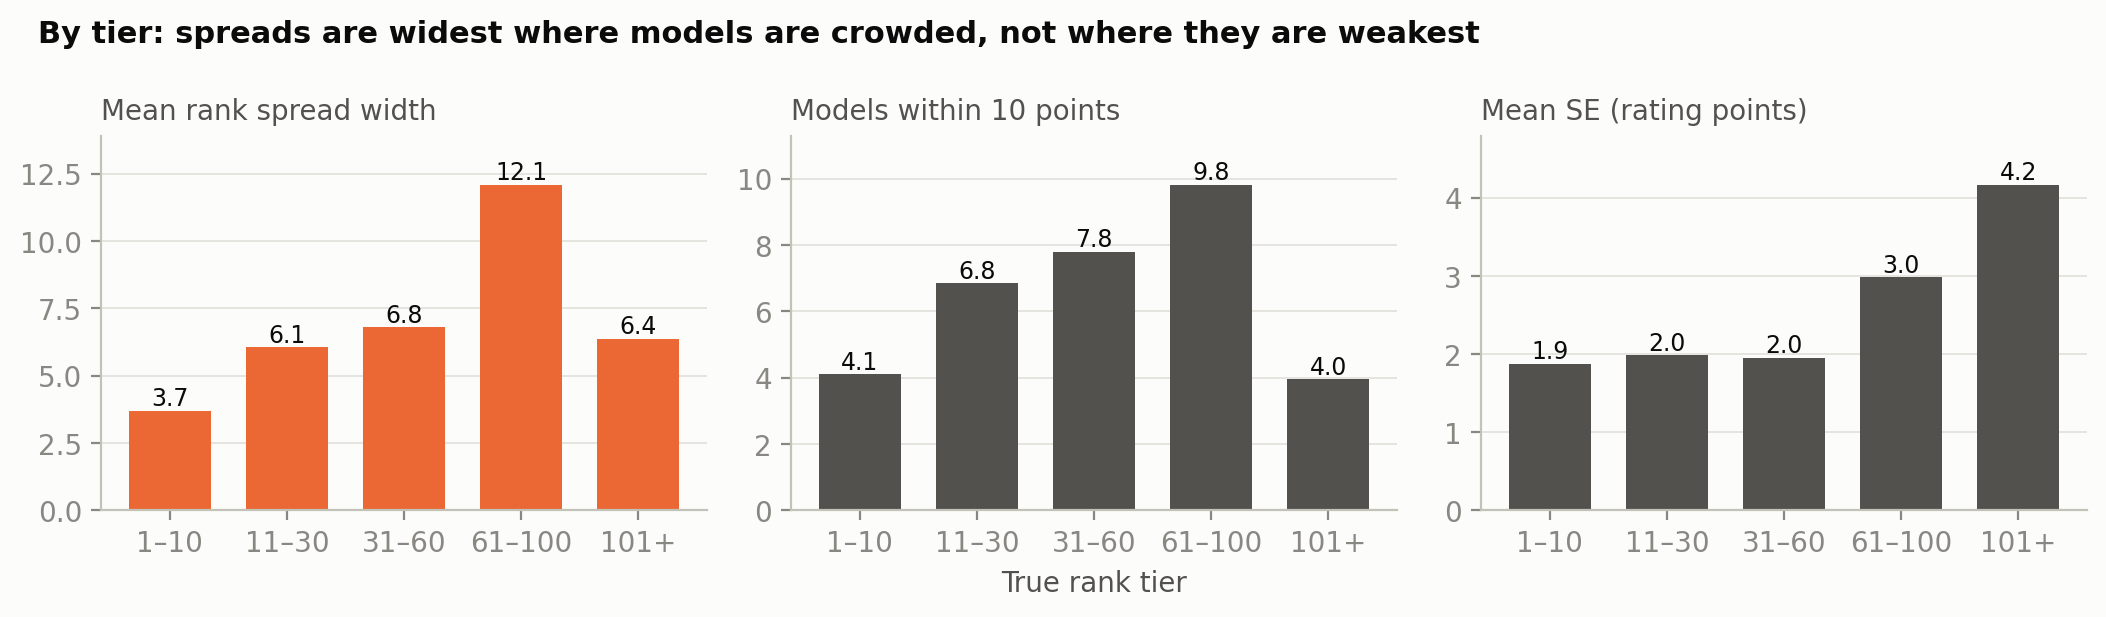

In [4]:
show("q1_tiers.png")

## 3. Q2: do multiplicity-corrected procedures fix it, and at what cost?

The same 1,000 simulated datasets, with every procedure run side by side:

- **Bonferroni:** each score interval at level 5%/M, so z = 3.55 instead of 1.96.
- **χ² projection:** the simultaneous confidence set of Chiang et al. (2024), projected onto each model.
- **χ² Scheffé:** the same set, read through pairwise differences.
- **Pairwise tests:** each of the 8,256 pairs tested directly, using the full covariance. The error control is Bonferroni, Holm's step-down, or Holm on the one-sided hypotheses (the version whose control of wrong directions is proven).

A procedure declares "A above B" when the score intervals do not overlap (interval methods) or when the test is significant (pairwise methods).

In [5]:
q2 = read("q2_summary.csv", index_col=0)
real = read("q2_real.csv")                        # real 2024 fit, sorted by rating
PROCS = {"arena": "Arena (uncorrected)", "bonferroni": "Bonferroni", "chi2": "χ² projection", "chi2_scheffe": "χ² Scheffé",
         "pairwise_bonferroni": "Pairwise Bonferroni", "holm_onesided": "Holm, one-sided", "holm": "Holm"}
top = real.iloc[0]
pd.DataFrame({name: {
    "All rank spreads right at once": pct(q2.loc["rank interval coverage, simultaneous (all models)", p]),
    "Mean rank spread width": f"{q2.loc['rank interval width, mean', p]:.1f}",
    "True orderings declared": pct(q2.loc["[declared orderings] power: share of true orderings declared", p]),
    "Datasets with any wrong ordering": pct(q2.loc["[declared orderings] P(any false ordering)", p]),
    f"Top model on the real board ({top.model})": f"{top[p + '_best']}–{top[p + '_worst']}",
} for p, name in PROCS.items()})

,Arena (uncorrected),Bonferroni,χ² projection,χ² Scheffé,Pairwise Bonferroni,"Holm, one-sided",Holm
All rank spreads right at once,90.9%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
Mean rank spread width,8.0,13.6,43.4,33.1,12.7,12.4,11.3
True orderings declared,94.5%,90.1%,66.9%,74.9%,90.8%,91.1%,92.0%
Datasets with any wrong ordering,15.5%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Top model on the real board (chatgpt-4o-latest),1–1,1–2,1–10,1–4,1–1,1–1,1–1


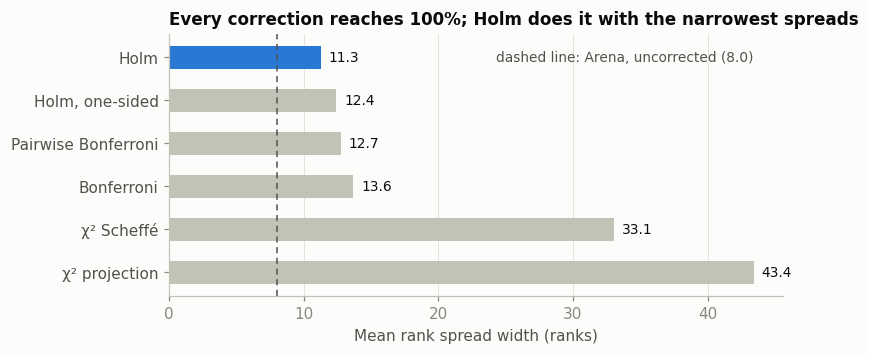

In [6]:
valid = ["holm", "holm_onesided", "pairwise_bonferroni", "bonferroni", "chi2_scheffe", "chi2"]
width = q2.loc["rank interval width, mean"]
fig, ax = plt.subplots(figsize=(7.2, 3.1))
y = np.arange(len(valid))
ax.barh(y, width[valid], height=0.55, color=[BLUE if p == "holm" else AXIS for p in valid], zorder=2)
for yi, p in zip(y, valid):
    ax.text(width[p] + 0.6, yi, f"{width[p]:.1f}", va="center", color=INK, fontsize=9)
ax.axvline(width["arena"], color=INK2, lw=1, ls=(0, (4, 3)), zorder=3)
ax.text(width.max(), 0, f"dashed line: Arena, uncorrected ({width['arena']:.1f})", ha="right", va="center", color=INK2, fontsize=9)
ax.set_yticks(y, [PROCS[p] for p in valid])
ax.tick_params(axis="y", labelcolor=INK2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean rank spread width (ranks)")
ax.set_title("Every correction reaches 100%; Holm does it with the narrowest spreads")
plt.show()

In [7]:
sweep = read("q2_sweep.csv")
z_need = sweep.loc[sweep.rs_all_cover >= 0.95, "z"].min()
at = sweep.set_index("z").loc[z_need]
print(f"Multiplier sweep (oracle benchmark): z = {z_need:.2f} already gives {pct(at.rs_all_cover)} simultaneous coverage "
      f"with mean width {at.rs_width:.1f}, {pct(at.rs_width / width['arena'] - 1, 0)} wider than Arena's.")
pairs = read("q2_real_pairs.csv")
print(f"Real 2024 board: Arena declares {pairs.arena.sum():,} orderings and Holm {pairs.holm.sum():,}. "
      f"Holm drops {(pairs.arena & ~pairs.holm).sum()} of Arena's and adds {(pairs.holm & ~pairs.arena).sum()}.")

Multiplier sweep (oracle benchmark): z = 2.10 already gives 95.6% simultaneous coverage with mean width 8.5, 6% wider than Arena's.
Real 2024 board: Arena declares 7,808 orderings and Holm 7,585. Holm drops 223 of Arena's and adds 0.


- **All corrections are valid in this world but overshoot.** Rank spreads already reach 95% at z ≈ 2.1. This oracle benchmark uses the true ranks, so it cannot be applied to real data, but it shows that the overlap rule already supplies most of the protection.
- **The χ² set protects far more than a ranking needs.** It covers every linear combination of the 129 scores, so it gives rank spreads 33–43 ranks wide.
- **Pairwise tests with Holm are the best trade-off.** They are 18% narrower than Bonferroni. Testing each gap directly instead of checking whether intervals overlap saves 0.9 ranks, and Holm's step-down saves 1.5 more. The textbook (two-sided) Holm is not proven to control wrong directions for close but untied pairs when the tests are correlated. The proven one-sided version gives 12.4.

**Stress tests.** Same battles, different true strengths. The table shows the share of datasets in which all rank spreads are right at once:

In [8]:
WORLDS = {"": "2024 strengths (default)", "_scale0.5": "strengths × 0.5", "_scale0.25": "strengths × 0.25",
          "_scale0.1": "strengths × 0.1", "_scale0": "all models exactly tied", "_tiers20": "20 tiers of exactly tied models",
          "_tiers10": "10 tiers of exactly tied models", "_tiers20s0.05": "20 tiers, near ties (spread 0.05)",
          "_tiers20s0.1": "20 tiers, near ties (spread 0.1)", "_tiers20s0.2": "20 tiers, near ties (spread 0.2)"}
show_procs = ["arena", "bonferroni", "pairwise_bonferroni", "holm_onesided", "holm"]
stress = pd.DataFrame({label: read(f"q2{tag}_summary.csv", index_col=0)
                       .loc["rank interval coverage, simultaneous (all models)", show_procs] for tag, label in WORLDS.items()}).T
stress.rename(columns=PROCS).map(pct)

,Arena (uncorrected),Bonferroni,Pairwise Bonferroni,"Holm, one-sided",Holm
2024 strengths (default),90.9%,100.0%,100.0%,100.0%,100.0%
strengths × 0.5,90.1%,100.0%,100.0%,100.0%,100.0%
strengths × 0.25,91.4%,100.0%,100.0%,100.0%,100.0%
strengths × 0.1,91.5%,100.0%,100.0%,100.0%,100.0%
all models exactly tied,0.2%,98.4%,97.3%,97.3%,97.3%
20 tiers of exactly tied models,24.1%,100.0%,99.8%,99.6%,97.5%
10 tiers of exactly tied models,7.3%,99.9%,99.8%,99.5%,96.6%
"20 tiers, near ties (spread 0.05)",66.8%,100.0%,99.9%,99.9%,99.4%
"20 tiers, near ties (spread 0.1)",70.3%,100.0%,100.0%,100.0%,99.8%
"20 tiers, near ties (spread 0.2)",78.2%,100.0%,100.0%,100.0%,100.0%


Arena's uncorrected rank spreads collapse once models are tied: 7–24% with tiers of exactly tied models, 0.2% when every model is tied, and 67–78% with near ties. The corrected procedures stay at or above 95%. Exact ties are where the error bounds are tight, and there Holm is at 96.6–97.5%.

## 4. Q3: are category specialties real?

For each (model, category) pair with at least 200 battles in the category (958 of 1,032 pairs, 8 categories), a z-score compares the model's score in that category with what its overall strength predicts. The overall fit uses the category's battles too, so each z is standardized against its own null mean and SD from 500 simulated "no specialty" datasets.

**Step 0: do our categories match the official ones?** Each category is rebuilt from the dump's prompt tags and compared with the official 2024 category board:

In [9]:
c0 = read("q3_step0_summary.csv")
c0.assign(**{"models within ±10 battles": c0.battles_within_10.astype(str) + " of " + c0.models.astype(str),
             "tested models (≥ 200 battles)": c0.models_ge_200,
             "specialty correlation with official (tested models)": c0.specialty_corr_ge_200.round(4)}) \
  .set_index("category")[["battles", "models within ±10 battles", "tested models (≥ 200 battles)",
                          "specialty correlation with official (tested models)"]]

,battles,models within ±10 battles,tested models (≥ 200 battles),specialty correlation with official (tested models)
category,,,,
coding,316372,98 of 128,126,0.9996
math,214348,98 of 128,124,0.9996
instruction_following,581492,97 of 128,127,0.9998
hard_prompts,447819,98 of 128,127,0.9994
chinese,176016,100 of 128,113,0.9998
russian,143973,99 of 128,93,0.9990
multi_turn,244413,98 of 128,126,0.9995
long_query,164230,99 of 128,106,0.9994


**Step 1: is there any specialty at all?** Each global test is compared with its null distribution, from the same 500 simulated null datasets:

In [10]:
g = read("q3_global.csv").set_index("statistic").drop(index="min_p")
g.index = g.index.map({"max_abs_z": "min-P (max |z|)", "chi2": "χ²", "hc": "HC", "hc_plus": "HC+"})
g[["observed", "null_median", "null_95", "p_bootstrap"]].map(lambda x: f"{x:.3g}")

,observed,null_median,null_95,p_bootstrap
statistic,,,,
min-P (max |z|),40.3,3.35,4.05,0.002
χ²,2.12e+04,954,1.03e+03,0.002
HC,1.22e+62,1.77,4.42,0.002
HC+,330,1.58,3.07,0.002


All four tests reject at p = 1/501, the smallest p-value 500 null draws can give. Plain HC is about 10^62: the smallest p-value is 0 and is dropped, and the second smallest, 2.8e-127, makes HC huge. That is why HC+ (which uses only p > 1/N) is the usable version here.

**Step 2: which pairs?**

In [11]:
q3 = read("q3_pairs.csv")
N = len(q3)
models_with = q3.groupby("model").bonferroni.any()
print(f"{N} tested pairs. Bonferroni (FWER 5%): {q3.bonferroni.sum()}; BH (FDR 10%): {q3.bh.sum()}; "
      f"naive p < 0.05: {(q3.p < 0.05).sum()} (about {0.05 * N:.0f} expected by chance).")
print(f"{models_with.sum()} of {len(models_with)} models have at least one Bonferroni specialty; "
      f"median size {q3.loc[q3.bonferroni, 'specialty_points'].abs().median():.0f} rating points.")
q3.loc[q3.z.abs().sort_values(ascending=False).index[:8], ["category", "model", "battles", "specialty_points", "z"]] \
  .round({"specialty_points": 1, "z": 1}).reset_index(drop=True)

958 tested pairs. Bonferroni (FWER 5%): 275; BH (FDR 10%): 525; naive p < 0.05: 521 (about 48 expected by chance).
94 of 129 models have at least one Bonferroni specialty; median size 25 rating points.


,category,model,battles,specialty_points,z
0,chinese,llama-3-70b-instruct,16254,-72.9,-40.3
1,chinese,llama-3-8b-instruct,10946,-59.3,-24.0
2,russian,llama-3-70b-instruct,15647,-41.7,-20.0
3,instruction_following,gpt-4-0613,29716,27.4,19.0
4,russian,claude-3-opus-20240229,15501,38.9,18.4
5,chinese,llama-2-70b-chat,3752,-78.7,-16.8
6,math,command-r-plus,10258,-36.3,-16.2
7,math,command-r,7014,-42.8,-15.2


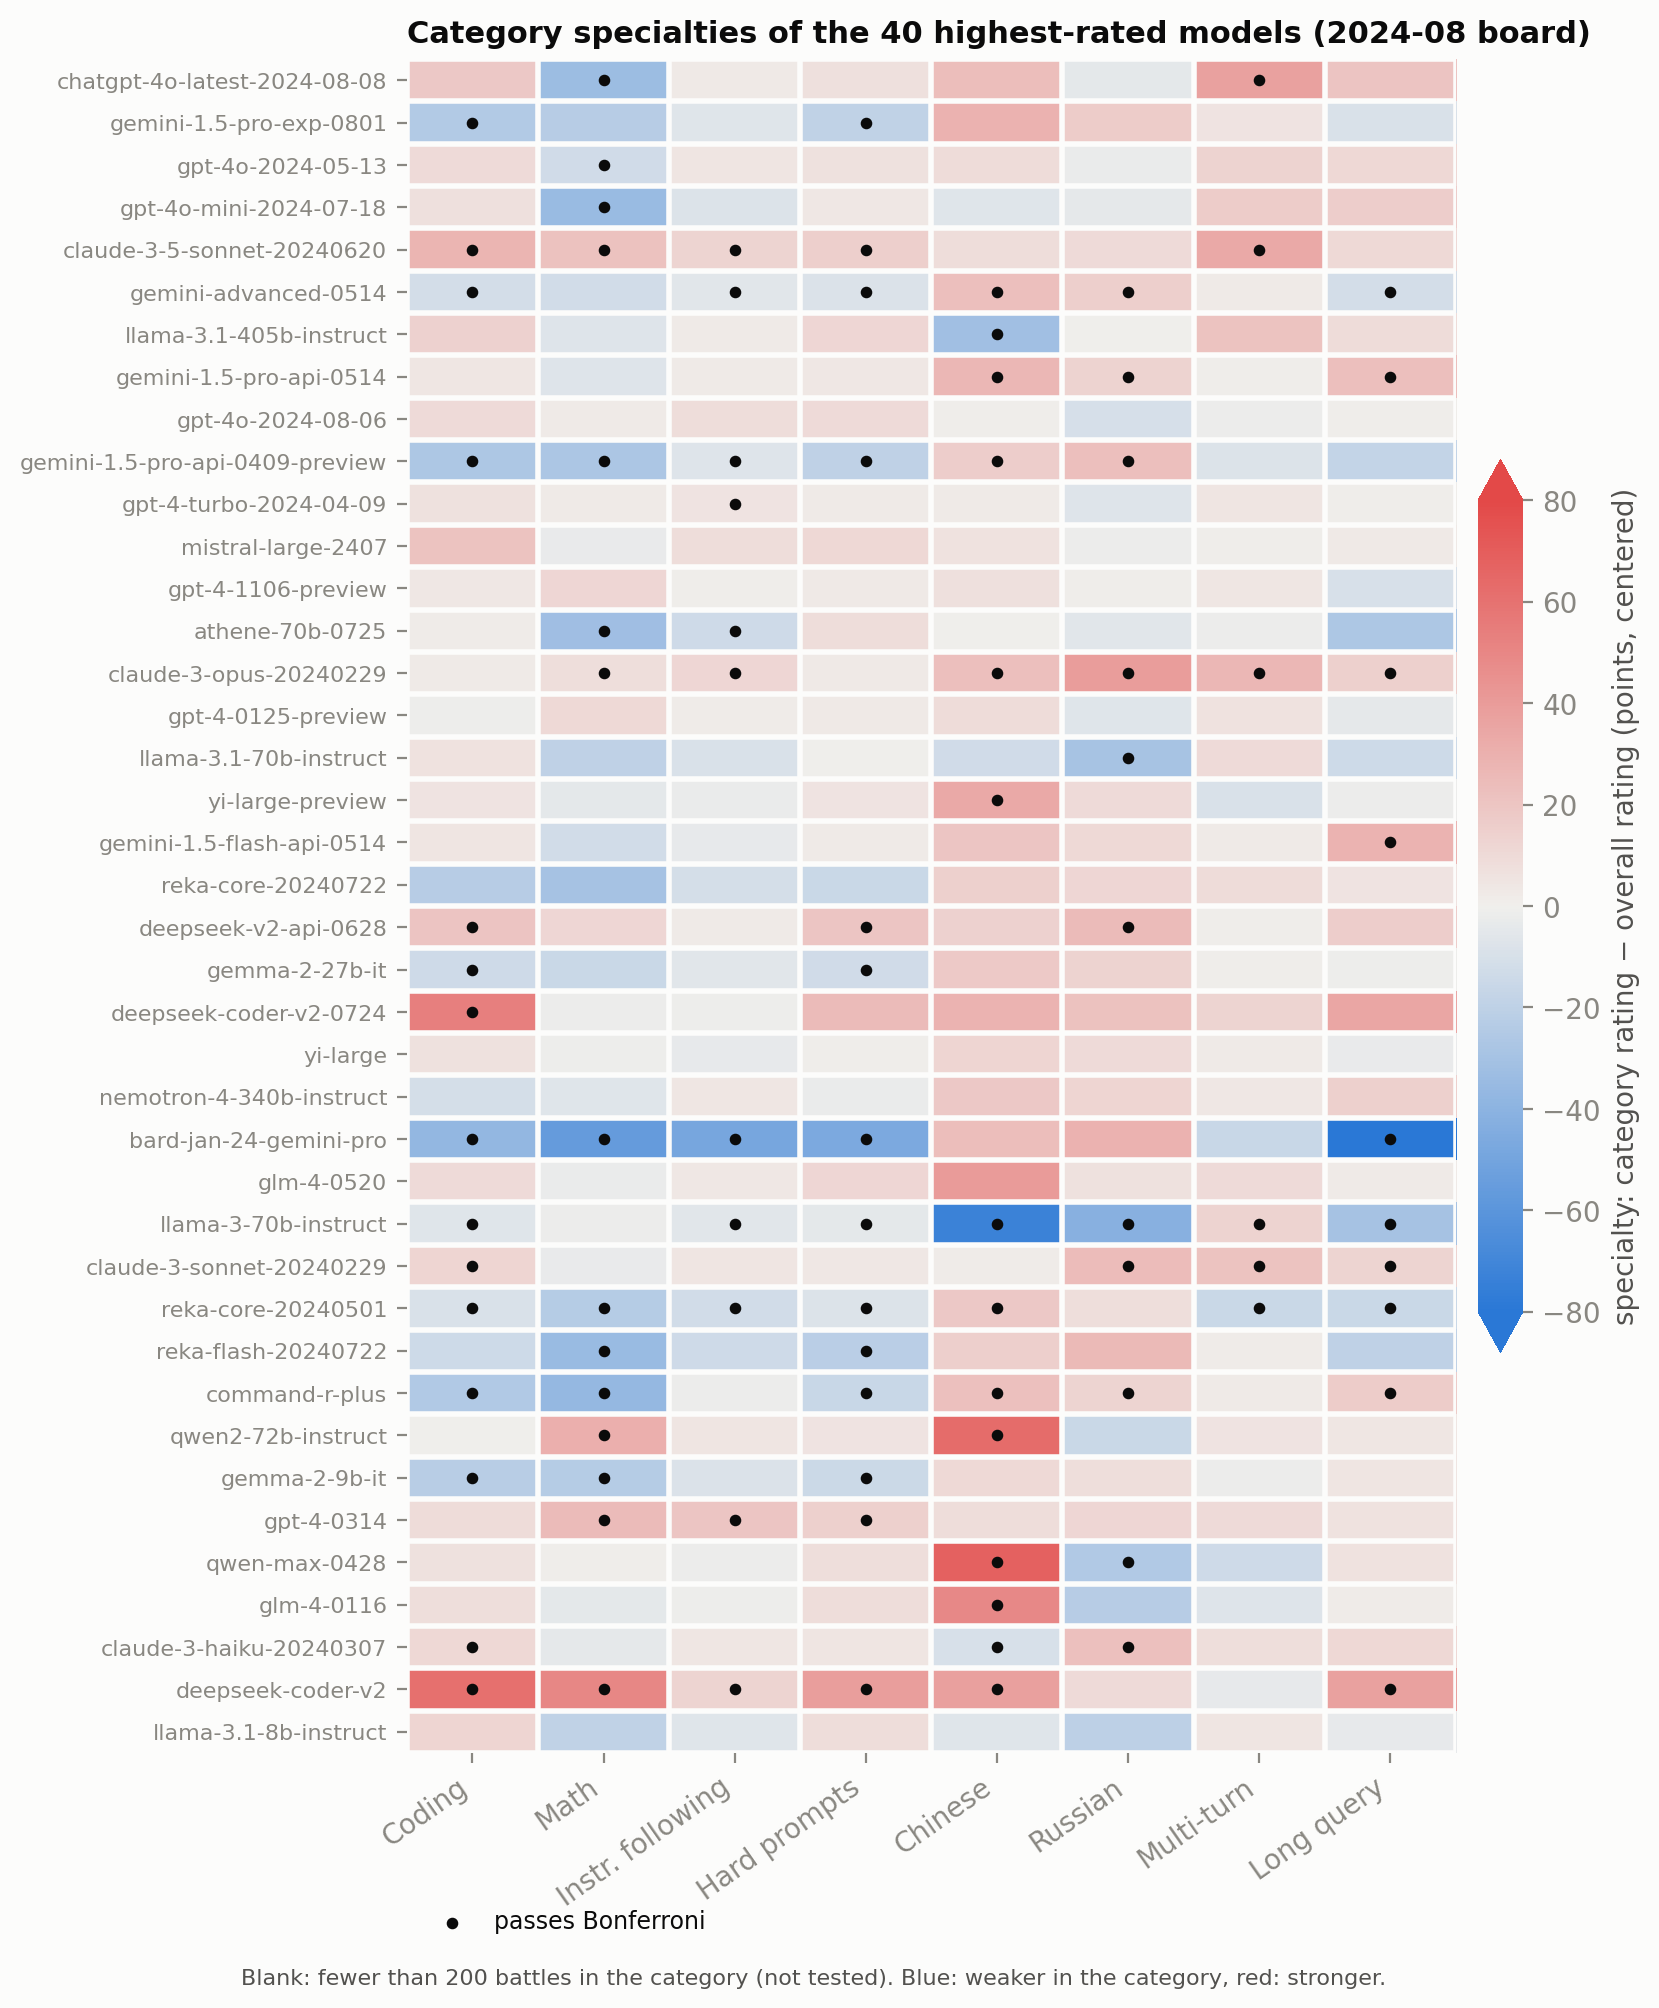

In [12]:
show("q3_specialties.png", width=820)

The strongest signals are language effects. Llama models are 40–80 points weaker in Chinese (Llama-3-70B: −73 points, z = −40) and Llama-3-70B also in Russian, while 8 of the 9 Qwen models are 50–84 points stronger in Chinese.

**Step 3: how much power do the tests have? Phase diagrams.** `q3_sim.py` plants s = N^(1−ϑ) specialties of strength μ = √(2 r log N) (in z units) into the same simulated Arena, following the Rare/Weak model from lecture. It then measures how often each global test detects them, with 200 datasets per cell. In each panel below, colour is power, the orange line is the test's theoretical detection boundary as N → ∞ (above it the test succeeds), and the black dots mark where the simulated power reaches 50%.

The boundaries are those of Donoho & Jin (2004):

- **HC:** detects any r > 0 when ϑ ≤ 1/2, and r > ϑ − 1/2 for 1/2 < ϑ ≤ 3/4.
- **min-P (max |z|):** needs r > (1 − √(1 − ϑ))².
- **χ²:** detects any fixed r when ϑ < 1/2 and nothing beyond.

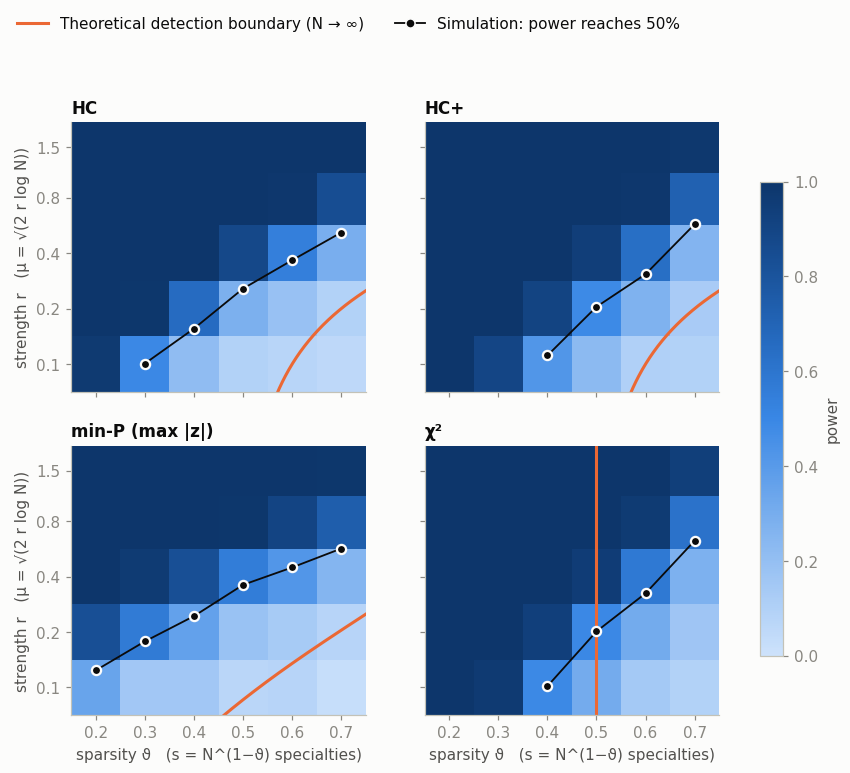

ϑ (HC+ power),0.2,0.3,0.4,0.5,0.6,0.7
r,,,,,,
0.1,1.0,0.9,0.42,0.23,0.10,0.10
0.2,1.0,1.0,0.91,0.48,0.27,0.13
0.4,1.0,1.0,1.00,0.94,0.64,0.26
0.8,1.0,1.0,1.00,1.00,0.99,0.72
1.5,1.0,1.0,1.00,1.00,1.00,0.98


In [13]:
sim = read("q3_sim.csv")
grid = sim[sim.theta.notna()]
thetas, rs = np.array(sorted(grid.theta.unique())), np.array(sorted(grid.r.unique()))


def edges(v, log=False):
    v = np.log(v) if log else np.asarray(v, dtype=float)
    mid = (v[1:] + v[:-1]) / 2
    e = np.r_[2 * v[0] - mid[0], mid, 2 * v[-1] - mid[-1]]
    return np.exp(e) if log else e


def r_at_half(g, key):
    # strength r at which power crosses 0.5, interpolated on log r; NaN if the grid never crosses it
    g = g.sort_values("r")
    p, r = g[key].values, g.r.values
    if p[0] >= 0.5 or p[-1] < 0.5:
        return np.nan
    i = int(np.argmax(p >= 0.5))
    return float(np.exp(np.interp(0.5, [p[i - 1], p[i]], np.log([r[i - 1], r[i]]))))


xe, ye = edges(thetas), edges(rs, log=True)
cmap = LinearSegmentedColormap.from_list("power", RAMP)
t = np.linspace(xe[0], xe[-1], 400)
hc_bound = np.where(t <= 0.5, np.nan, t - 0.5)
TESTS = [("hc", "HC", hc_bound), ("hc_plus", "HC+", hc_bound),
         ("max_abs_z", "min-P (max |z|)", (1 - np.sqrt(1 - t)) ** 2), ("chi2", "χ²", None)]


def phase_panel(ax, key, title, bound):
    P = grid.pivot(index="r", columns="theta", values=key).loc[rs, thetas].values
    mesh = ax.pcolormesh(xe, ye, P, cmap=cmap, vmin=0, vmax=1, shading="flat")
    if bound is None:
        ax.axvline(0.5, color=ORANGE, lw=2)
    else:
        ax.plot(t, np.where(bound > 0, bound, np.nan), color=ORANGE, lw=2)
    r50 = [r_at_half(grid[grid.theta == th], key) for th in thetas]
    ax.plot(thetas, r50, color=INK, lw=1.2, marker="o", ms=6, mfc=INK, mec=SURFACE, mew=1.5)
    ax.set_yscale("log")
    ax.set_xlim(xe[0], xe[-1]); ax.set_ylim(ye[0], ye[-1])
    ax.set_xticks(thetas); ax.set_yticks(rs, [f"{r:g}" for r in rs]); ax.minorticks_off()
    ax.grid(False)
    ax.set_title(title)
    return mesh


fig, axes = plt.subplots(2, 2, figsize=(9.5, 7), sharex=True, sharey=True)
for ax, (key, title, bound) in zip(axes.flat, TESTS):
    mesh = phase_panel(ax, key, title, bound)
for ax in axes[1]:
    ax.set_xlabel("sparsity ϑ   (s = N^(1−ϑ) specialties)")
for ax in axes[:, 0]:
    ax.set_ylabel("strength r   (μ = √(2 r log N))")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="power")
fig.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label="Theoretical detection boundary (N → ∞)"),
                    Line2D([], [], color=INK, lw=1.2, marker="o", mec=SURFACE, label="Simulation: power reaches 50%")],
           loc="lower left", bbox_to_anchor=(0.06, 0.98), ncol=2)
plt.show()

grid.pivot(index="r", columns="theta", values="hc_plus").round(2).rename_axis(index="r", columns="ϑ (HC+ power)")

- **The ordering matches the theory.** χ² and HC/HC+ are strongest when specialties are many (small ϑ). min-P is far behind there and catches up only as specialties become few, as Donoho & Jin predict.
- **N = 958 is far from asymptotic.** The 50% power points sit well above the theoretical boundaries: for example, HC needs r ≈ 0.5 at ϑ = 0.7, where the limit is 0.2. χ² still has power at ϑ = 0.6–0.7, beyond its asymptotic limit of 1/2. With log N ≈ 6.9, the boundaries describe the direction of the trade-offs, not where they occur.
- **The grid stops at ϑ = 0.7 (8 specialties).** The very sparse region, where HC's advantage over min-P is largest in theory, is not covered.

**Identification.** The same grid, coloured by the share of planted specialties that BH and Bonferroni find. The orange line r = ϑ is the boundary for almost full recovery: a threshold at √(2ϑ log N) separates the N^(1−ϑ) signals from the N nulls only when the signals are stronger than it.

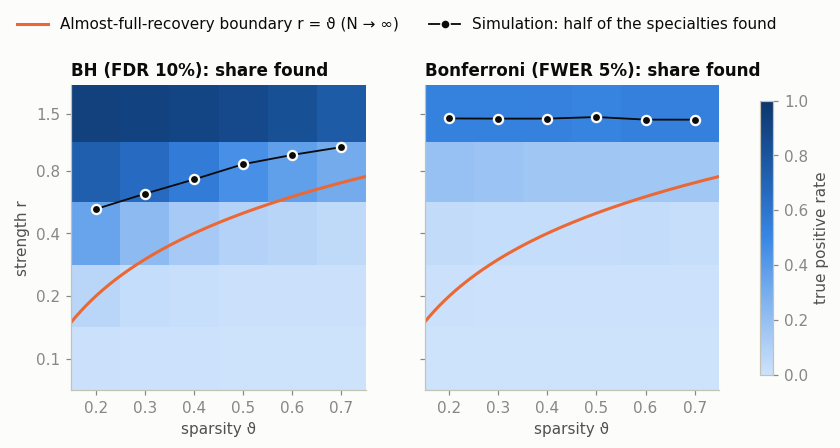

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, (key, title) in zip(axes, [("bh_tpr", "BH (FDR 10%): share found"), ("bonf_tpr", "Bonferroni (FWER 5%): share found")]):
    mesh = phase_panel(ax, key, title, t)
    ax.set_xlabel("sparsity ϑ")
axes[0].set_ylabel("strength r")
fig.colorbar(mesh, ax=axes, shrink=0.9, label="true positive rate")
fig.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label="Almost-full-recovery boundary r = ϑ (N → ∞)"),
                    Line2D([], [], color=INK, lw=1.2, marker="o", mec=SURFACE, label="Simulation: half of the specialties found")],
           loc="lower left", bbox_to_anchor=(0.06, 0.98), ncol=2)
plt.show()

Between the detection boundary and r = ϑ lies the "detectable but not identifiable" region. There HC can say that specialties exist, but no procedure can say which ones. In the simulation BH finds half of the planted specialties at r ≈ 0.5 (dense) to 1.0 (sparse). Bonferroni needs r ≈ 1.4 at every sparsity, and finds only about 16% at r = 0.8.

On the real board the global tests reject by a very wide margin, and many pairs are individually significant, so the real data lie far into the easy corner of these diagrams. That holds if the null's noise level is right. Section 6 shows how sensitive the count is to that.

## 5. Limitations

- **Single world.** Q1 and Q2 simulate one world: 129 models with 2024 strengths. Today's site ranks about 400 models, where Bonferroni would need z = 3.84. The stress tests vary the strengths but not the number of models.
- **Idealized simulation.** It assumes independent battles, an exact Bradley–Terry model, fixed strengths and one tie rate. Real coverage is probably lower.
- **Q3's null is exact Bradley–Terry with fixed strengths.** Anything else that varies by category shows up as a "specialty", such as strengths drifting over time while the category mix changes, or voters who differ by language. So does extra noise from correlated votes (Section 6).
- **One snapshot.** Only the 2024-08 snapshot is used for Q1–Q3. The 2026 check covers only the interval type and the rank-spread formula.

## 6. Checks on the code and results (2026-10-29)

We reran the scripts from a clean data download and compared every output with the committed files. Two independent reviews also read the Q2 and Q3 code and checked every number in the README and the notebooks against the results.

### 6.1 Reproduction


Each script was rerun on 2026-10-29 with Python 3.12 and the pinned requirements. Its outputs were compared with the committed versions (`git show HEAD:<file>`), and the committed files were then restored.

| Script | Compared | Result |
|---|---|---|
| `step0.py` | `step0_comparison.csv`, printed checks | Identical except float noise (≤ 6e-14); every number in the README reproduced. Run on 2026-10-20; the code changed since only by moving two constants to `arena_data.py` |
| `test_simulate.py` | simulator vs arena-rank, unbiasedness | Passed (max rating difference 9e-10; mean \|bias\| / MC SE = 0.80) |
| `test_pairwise.py` | pairwise procedures vs `statsmodels`; nesting, antisymmetry, transitivity; real fit | Passed. It first failed only because `statsmodels` was missing from an older environment; `pip install -r requirements.txt` fixes that |
| `q1.py --reps 1000` | `q1_summary.csv`, `q1_per_model.csv`, `q1.npz` | Identical except float noise (≤ 2e-13). Run on 2026-10-20; `q1.py`, `simulate.py` and `ranking.py` are unchanged since. `q2.py` also reconfirms all 1,000 Arena rank spreads today |
| `q2.py --reps 1000`, all seven procedures | summary, per-model, sweep, real, real pairs, `q2.npz`, `q2_real_cov.npz` | Summary and sweep identical; the rest differ by float noise only (≤ 5e-12). Arena's rank spreads are identical to `q1.npz` |
| `q2.py --tiers 20`, all seven procedures | `q2_tiers20_*.csv` | Identical except float noise (≤ 4e-15) |
| `q3_step0.py` | `q3_step0_summary.csv`, `q3_step0_comparison.csv` | Identical |
| `q3.py --reps 500` | `q3_pairs.csv`, `q3_global.csv`, `q3_null.npz` | Identical |
| `step0_2026.py` | `step0_2026_rank_spread.csv`, `step0_2026_intervals.csv` | Rank spreads identical (59 of 59). The interval table now has 4,831 boards instead of 4,773, because `leaderboard-dataset` has added boards since; all are still exactly 1.9600. The script always downloads the latest version, so this file will keep growing |

Not rerun: the eight other Q2 stress worlds (about 4 minutes each) and `q3_sim.py` (about 35 minutes). Their scripts share the code paths checked above, and the reviews checked their committed numbers against the README.

### 6.2 Review findings

**No statistical or coding errors were found in the procedures.** This was checked for the Bradley–Terry fit and the covariance, Bonferroni, both χ² versions, the three pairwise procedures (which agree with `statsmodels`), the rank intervals, the stress worlds, the Q3 z-statistic (including the tie-aware variance), HC/HC+, BH, Bonferroni and the power simulation. Every number in the README matches the committed results. The findings below are about claims, labels and robustness. Each one is shown from the committed files.

**(a) "Wrong ordering" is defined two ways across the Q2 notebooks.** The README, the Holm notebook and Section 3 above count an ordering when the procedure declares it, i.e. when the score intervals do not overlap. The Bonferroni notebook counted it only when the rank spreads do not overlap, the site's tie rule. Both are legitimate, but they differ a lot for Arena:

In [15]:
rules = {"score intervals don't overlap (declared)": "[declared orderings]", "rank spreads don't overlap (site's rule)": "[rank intervals don't overlap]"}
pd.DataFrame({f"{p}: {what}": {rule: pct(q2.loc[f"{pre} {m}", p]) for rule, pre in rules.items()}
              for p in ["arena", "bonferroni"]
              for what, m in [("any wrong ordering", "P(any false ordering)"), ("true orderings found", "power: share of true orderings declared")]}).T

,score intervals don't overlap (declared),rank spreads don't overlap (site's rule)
arena: any wrong ordering,15.5%,0.6%
arena: true orderings found,94.5%,90.0%
bonferroni: any wrong ordering,0.0%,0.0%
bonferroni: true orderings found,90.1%,81.4%


**(b) Q3's count of specialties is sensitive to the null's noise level.** The null SD of each z comes from independent multinomial redraws. It ignores correlated votes (same user or session, time clusters) and misfit of the Bradley–Terry model. On the real board the standardized z have a robust SD of about 3.3, against 1 under the null. If the true noise were larger, the Bonferroni count would shrink quickly:

In [16]:
crit = norm.isf(0.05 / (2 * N))
robust_sd = 1.4826 * np.median(np.abs(q3.z - q3.z.median()))
print(f"robust SD of the real z*: {robust_sd:.2f}")
pd.DataFrame({"Bonferroni discoveries": {f"null SD × {f:g}": int((q3.z.abs() / f > crit).sum()) for f in [1, 1.5, 2, 3]}})

robust SD of the real z*: 3.29


,Bonferroni discoveries
null SD × 1,275
null SD × 1.5,149
null SD × 2,76
null SD × 3,26


"Some specialties exist" is robust: even with 3 times the noise, 26 pairs remain. The README's "275 of 958, neither rare nor weak" is not. It should be stated as conditional on the null, and a check with clustered noise (e.g. a bootstrap by day or by user session) would settle it.

**(c) Two README statements about Q3 are wrong.**

In [17]:
p_sorted = np.sort(2 * norm.sf(q3.z.abs()))
cells = grid[grid.s > 0]
print(f"HC: p_(1) = {p_sorted[0]:.1e} (dropped as non-finite); the maximum is at k = 2, where p_(2) = {p_sorted[1]:.1e}.")
print(f"BH false discovery proportion across the power grid: {cells.bh_fdp.min():.3f} to {cells.bh_fdp.max():.3f} "
      f"(README: 'stays near 10% (0.09-0.12)'); at r = 1.5: {cells[cells.r == 1.5].bh_fdp.min():.3f} to {cells[cells.r == 1.5].bh_fdp.max():.3f}.")
print(f"Bonferroni P(any false discovery): {sim[sim.s == 0].bonf_any_false.dropna().iloc[0]:.3f} with no specialties, "
      f"up to {cells.bonf_any_false.max():.2f} on the grid (README: 'near 5%').")

HC: p_(1) = 0.0e+00 (dropped as non-finite); the maximum is at k = 2, where p_(2) = 2.8e-127.
BH false discovery proportion across the power grid: 0.014 to 0.122 (README: 'stays near 10% (0.09-0.12)'); at r = 1.5: 0.016 to 0.099.
Bonferroni P(any false discovery): 0.065 with no specialties, up to 0.09 on the grid (README: 'near 5%').


- **HC's size.** HC is not about 10^62 because p_(1) underflows. The underflowed p_(1) is dropped, and HC is huge because it grows like 1/√p for the tiny p_(2).
- **BH's FDP.** It does not stay at 0.09–0.12. It is often far below 10%, partly because discoveries in a planted model's other categories count as spillover, not as false.
- **Bonferroni's error rate.** It is a little above 5%, probably because each null SD is estimated from only 500 draws.

**(d) Smaller items.**
- **Q3 reuses its null draws.** `q3.py` uses the same 500 null draws to standardize z and to give the null 95% points, so those points are slightly low. With leave-one-out draws they are 1,036 for χ² (README 1,028) and 4.12 for max |z| (4.05). The p-values are unaffected.
- **"94 of the 129 models have at least one Bonferroni specialty, in every category"** reads as if every model had one in every category. The intended meaning is that every category has some (17–40% of its pairs).
- **Planted sizes in rating points.** The "27-point specialties" of the power simulation are a median over pairs: a fixed z-size corresponds to 5–91 points depending on the pair's data. They are not directly comparable with the real median of 25 points.
- **The proposal's low-rank-plus-sparse (SVD) step for Q3 was not implemented.**
- **Reproduce commands overwrite results.** The notebooks `q2_bonferroni` and `q2_chi2` give `q2.py` commands with fewer than all seven procedures. Running them rewrites `results/q2_*` without the other procedures' columns, and the other notebooks then fail.
- **`pairwise.py` docstring.** One paragraph is misplaced: the sentence about the one-sided threshold sits under "All guarantees are asymptotic". The text "every true score is distinct" is no longer true in the tied stress worlds.
- **`q2.py` only prints the Q1 consistency check; it does not assert it.** It passes in the current results.
- **The Bonferroni notebook's last takeaway** ("Holm may get closer to the z ≈ 2.1 benchmark") is now answered: Holm gives 11.3 ranks against the benchmark's 8.5.
- **The Holm notebook** says that models that "often play the same opponents" have positively correlated estimates. The review found that the data support "models that play each other often" instead, as the χ² notebook says. This was not re-derived here.

### 6.3 Suggested fixes before the final report

1. **Q3 wording.** Correct the two wrong README statements (HC's size, BH's FDP), say Bonferroni's error rate is a little above 5%, and clarify the "every category" sentence.
2. **Q3 interpretation.** State the specialty count as conditional on the null's noise level, and add the sensitivity table above or a clustered-noise check.
3. **Q2 consistency.** Use one definition of "wrong ordering" across the notebooks, or label both, and fix the reproduce commands to use all seven procedures.
4. **Code.** Fix the `pairwise.py` docstring, and turn the Q1 check in `q2.py` into an assert.
5. **Optional.** Extend the Q3 power grid to ϑ = 0.8–0.9 to cover the sparse corner of the phase diagram (about 10 more cells), and draw the phase diagrams in `q3_figures.py` so they live with the other figures.